# Logistic regression from scratch
Implementation and explanations by Alejandro.

In [142]:
import numpy as np
import pandas as pd

df_cancer = pd.read_csv("../data/breast_cancer.csv")


df_cancer.info()
df_cancer.describe()
df_cancer.head()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   radius_mean              569 non-null    float64
 1   texture_mean             569 non-null    float64
 2   perimeter_mean           569 non-null    float64
 3   area_mean                569 non-null    float64
 4   smoothness_mean          569 non-null    float64
 5   compactness_mean         569 non-null    float64
 6   concavity_mean           569 non-null    float64
 7   concave_points_mean      569 non-null    float64
 8   symmetry_mean            569 non-null    float64
 9   fractal_dimension_mean   569 non-null    float64
 10  radius_se                569 non-null    float64
 11  texture_se               569 non-null    float64
 12  perimeter_se             569 non-null    float64
 13  area_se                  569 non-null    float64
 14  smoothness_se            569 non-null

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [143]:
# Feature selection is not based on correlations with held-out labels.


In [144]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use all features
SELECTED_COLUMNS = df_cancer.columns.drop('target').tolist()
SELECTED_TARGET = ['target']
X_train, X_test, y_train, y_test = train_test_split(
    df_cancer[SELECTED_COLUMNS].to_numpy(),
    df_cancer[SELECTED_TARGET].to_numpy(),
    test_size=0.2, random_state=42, stratify=df_cancer['target'])
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# create LR Class

In [145]:
def sigmoid(x): 
    return 1 / (1 + np.exp(-x))

class NeuronLogisticRegression:
    """Public inputs: X (examples, features), Y (examples, 1)."""

    def __init__(self, feature_count, lr=0.1, seed=42):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.1, size=(1, feature_count))
        self.B = np.zeros((1, 1)) #simplifying to standard 0
        self.lr = lr

    def feedforward(self, X):
        # (1, nx) @ (nx, m) + (1, 1): transpose row-oriented inputs here.
        Z = self.W @ X.T + self.B
        return sigmoid(Z), Z

    def cost(self, A, Y):
        #keep probabilities away from 0 and 1 before taking logarithms.
        A = np.clip(A, 0.00001, 1 - 0.00001)
        return float(np.mean(-(Y.T * np.log(A) + (1 - Y.T) * np.log(1 - A))))

    def backwards(self, A, X, Y):
        dz = A - Y.T
        dw = dz @ X / len(X)
        db = dz.mean(keepdims=True)
        return dw, db

    def update(self, dw, db):
        self.W -= self.lr * dw
        self.B -= self.lr * db

    def fit(self, X, Y, epoch=1000):
        self.cost_values = []
        for _ in range(epoch):
            A, Z = self.feedforward(X)
            self.cost_values.append(self.cost(A, Y))
            dw, db = self.backwards(A, X, Y)
            self.update(dw, db)


nlr = NeuronLogisticRegression(X_train.shape[1])
nlr.fit(X_train, y_train)
THRESHOLD = 0.5
for name, X, Y in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
    A, Z = nlr.feedforward(X)
    accuracy = np.mean((A.T > THRESHOLD) == Y)
    print(f'{name} accuracy: {accuracy:.2%}; loss: {nlr.cost(A, Y):.4f}')


Train accuracy: 98.90%; loss: 0.0570
Test accuracy: 97.37%; loss: 0.0868


Text(0, 0.5, 'Mean training loss')

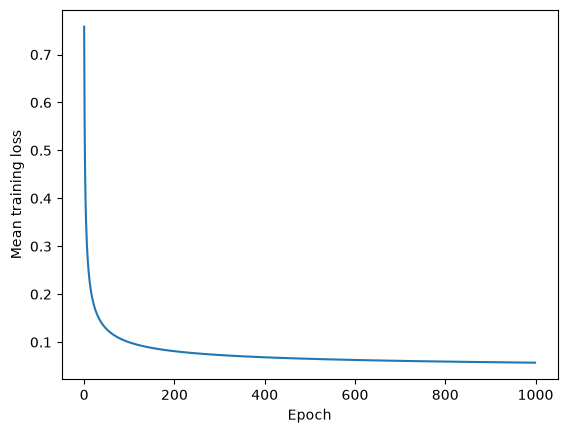

In [146]:
import matplotlib.pyplot as plt

plt.plot(nlr.cost_values)
plt.xlabel('Epoch')
plt.ylabel('Mean training loss')


# Gradient checking

In [147]:
A, Z = nlr.feedforward(X_train)
original_weight = nlr.W[0, 0]
dw, db = nlr.backwards(A, X_train, y_train)
original_cost = nlr.cost(A, y_train)
epsilon = 1e-5

try:
    nlr.W[0, 0] = original_weight + epsilon
    changed_A, _ = nlr.feedforward(X_train)
    numerical_slope = (nlr.cost(changed_A, y_train) - original_cost) / epsilon
    print('Numerical slope:', numerical_slope)
    print('Analytical slope:', dw[0, 0])
    print('Difference:', numerical_slope - dw[0, 0])
finally:
    nlr.W[0, 0] = original_weight


Numerical slope: 0.0005281188437955553
Analytical slope: 0.0005284686037883699
Difference: -3.4975999281463156e-07
